# Below Zero: analysis

This notebook reads only from the local cache in `data/raw/`. It never calls the API. To populate the cache, run the fetch script from the project root first, e.g. `python src/fetch.py 2024-04-07`.

## Stage 01: one day, end to end

One settlement day of Market Index Data (`MID`), the wholesale price series for phenomenon 1. The aim is to learn the response shape and the settlement-period conventions before looping over three years.

Day chosen: **Sunday 7 April 2024**, the 2024 day with the most negative `MID` periods (found with a one-off scan of 2024).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from plotnine import *

sys.path.append(str(Path("..") / "src"))
from fetch import mid_cache_path
from parse import parse_mid, periods_in_day

DAY = "2024-04-07"
FIG_DIR = Path("..") / "figures"

### What the raw response looks like

A JSON object with a `data` list, one record per provider per settlement period.

In [2]:
path = mid_cache_path(DAY)
raw = json.loads(path.read_text(encoding="utf-8"))
print("top-level keys:", list(raw))
for record in raw["data"][:2]:
    print(record)

raw_df = pd.DataFrame(raw["data"])
raw_df.groupby("dataProvider").agg(
    rows=("price", "size"),
    min_price=("price", "min"),
    max_price=("price", "max"),
    total_volume_mwh=("volume", "sum"),
)

top-level keys: ['data']
{'dataset': 'MID', 'startTime': '2024-04-07T22:30:00Z', 'dataProvider': 'APXMIDP', 'settlementDate': '2024-04-07', 'settlementPeriod': 48, 'price': 28.73, 'volume': 1553.0}
{'dataset': 'MID', 'startTime': '2024-04-07T22:30:00Z', 'dataProvider': 'N2EXMIDP', 'settlementDate': '2024-04-07', 'settlementPeriod': 48, 'price': 0.0, 'volume': 0.0}


,rows,min_price,max_price,total_volume_mwh
dataProvider,,,,
APXMIDP,48,-61.09,68.49,89213.75
N2EXMIDP,48,0.00,0.00,0.00


### Parsed: one row per settlement period

`parse_mid` keeps the APX rows only, builds the timestamp from `(settlementDate, settlementPeriod)`, checks it against the API's own `startTime`, and checks that every period 1..N is present exactly once.

In [3]:
mid = parse_mid(path)
negative = mid["price_gbp_mwh"] < 0
print(f"periods: {len(mid)}")
print(f"negative periods: {negative.sum()} ({negative.mean():.0%})")
print(f"lowest price: £{mid['price_gbp_mwh'].min():.2f}/MWh")
print(f"highest price: £{mid['price_gbp_mwh'].max():.2f}/MWh")
mid.head()

periods: 48
negative periods: 29 (60%)
lowest price: £-61.09/MWh
highest price: £68.49/MWh


,settlement_date,settlement_period,start_utc,start_local,price_gbp_mwh,volume_mwh
0,2024-04-07,1,2024-04-06 23:00:00+00:00,2024-04-07 00:00:00+01:00,-0.66,1436.95
1,2024-04-07,2,2024-04-06 23:30:00+00:00,2024-04-07 00:30:00+01:00,7.46,1578.60
2,2024-04-07,3,2024-04-07 00:00:00+00:00,2024-04-07 01:00:00+01:00,11.51,1801.35
3,2024-04-07,4,2024-04-07 00:30:00+00:00,2024-04-07 01:30:00+01:00,19.46,2043.65
4,2024-04-07,5,2024-04-07 01:00:00+00:00,2024-04-07 02:00:00+01:00,4.89,2170.00


### Clock-change check

The number of periods in a day comes from the length of the local day, never an assumed 48.

In [4]:
for d in ["2024-03-31", DAY, "2024-10-27"]:
    print(d, periods_in_day(d))

2024-03-31 46
2024-04-07 48
2024-10-27 50


### Chart

Drawn as steps because each price holds for the whole half hour. Negative periods are marked by both colour and shape, so the chart still reads in greyscale.

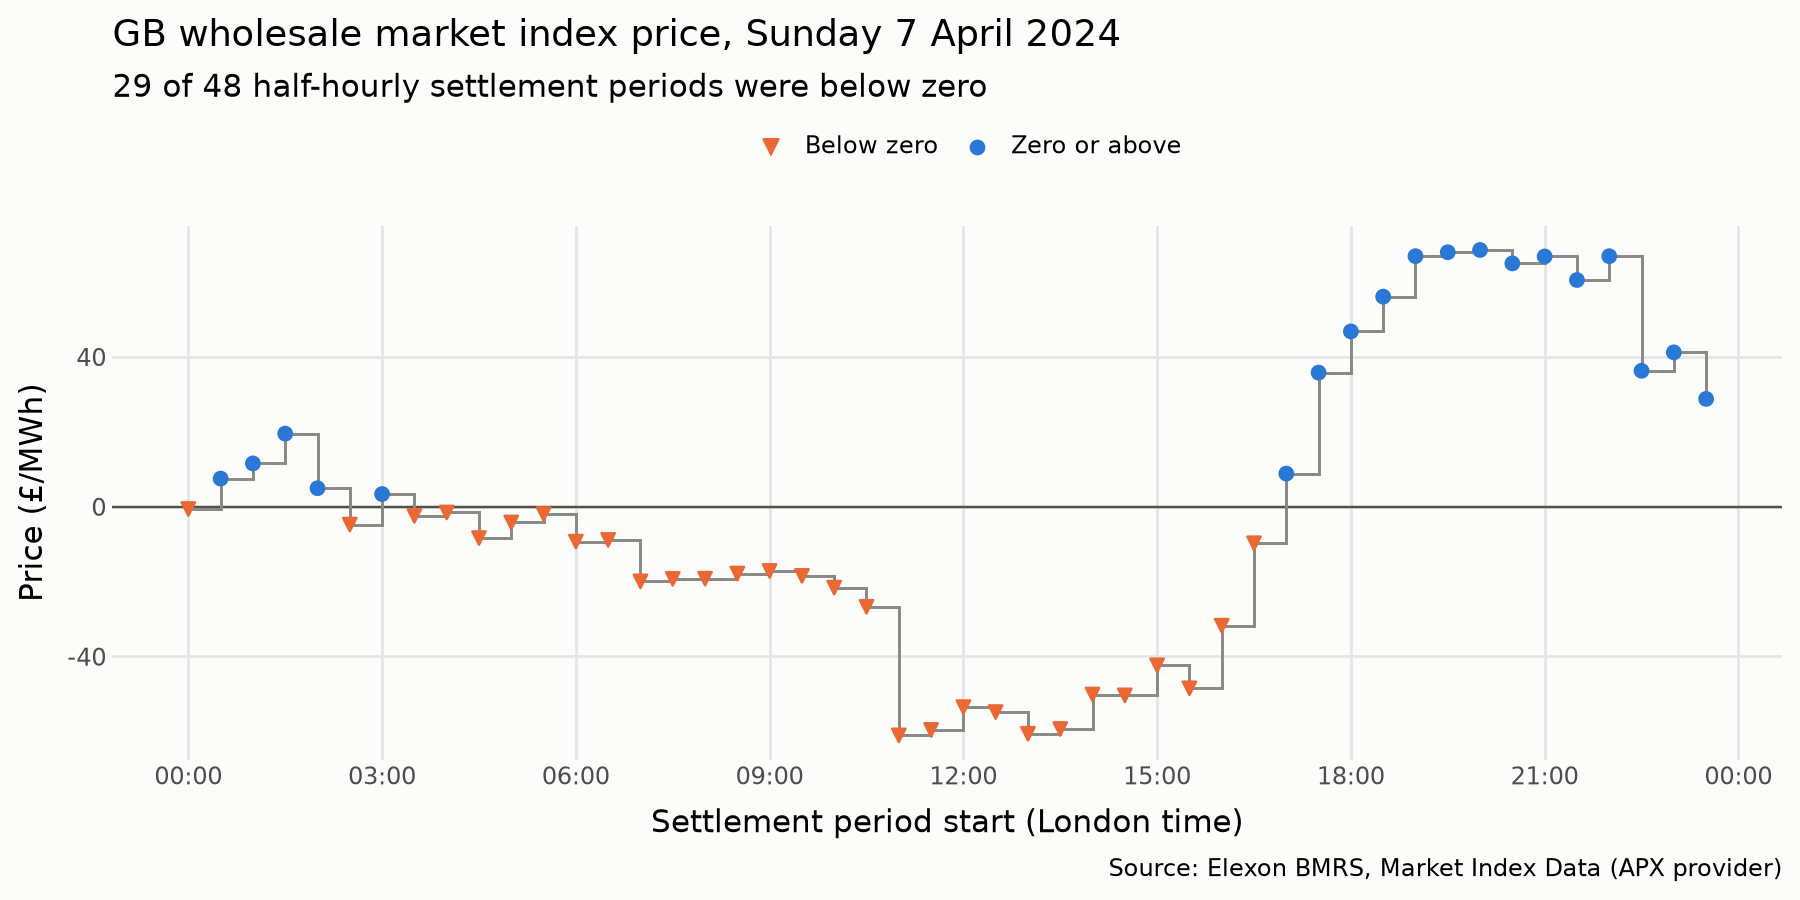

In [5]:
plot_df = mid.assign(
    # Local wall-clock time for the x-axis. Safe here because 7 April has no clock change.
    time=mid["start_local"].dt.tz_localize(None),
    sign=negative.map({True: "Below zero", False: "Zero or above"}),
)

fig = (
    ggplot(plot_df, aes("time", "price_gbp_mwh"))
    + geom_hline(yintercept=0, color="#52514e", size=0.5)
    # "hv" = flat for the half hour, then jump: each price applies to its whole period
    + geom_step(direction="hv", color="#8a8985", size=0.6)
    + geom_point(aes(color="sign", shape="sign"), size=2.2)
    + scale_color_manual(values={"Below zero": "#eb6834", "Zero or above": "#2a78d6"})
    + scale_shape_manual(values={"Below zero": "v", "Zero or above": "o"})
    + scale_x_datetime(date_labels="%H:%M", date_breaks="3 hours")
    + labs(
        title="GB wholesale market index price, Sunday 7 April 2024",
        subtitle=f"{negative.sum()} of {len(mid)} half-hourly settlement periods were below zero",
        x="Settlement period start (London time)",
        y="Price (£/MWh)",
        color="", shape="",
        caption="Source: Elexon BMRS, Market Index Data (APX provider)",
    )
    + theme_minimal(base_size=11)
    + theme(
        figure_size=(9, 4.5),
        legend_position="top",
        panel_grid_minor=element_blank(),
        plot_background=element_rect(fill="#fcfcfb", color="#fcfcfb"),
    )
)
fig.save(FIG_DIR / f"stage01_mid_{DAY}.png", dpi=150, verbose=False)
fig

## Stage 02: one day of balancing cost

The **Balancing Mechanism (BM)** is how NESO, the system operator, adjusts generation in real time. Each unit submits **bids** (prices to reduce output) and **offers** (prices to increase it). When NESO accepts a bid from a wind farm, the wind farm is being paid to switch off: this is **paid curtailment**.

Wind farms bid at *negative* prices because turning down loses them subsidy income (Renewables Obligation certificates or CfD payments), so NESO has to pay them to stop.

Datasets used, all for 7 April 2024:

| Dataset | What it gives | Granularity |
|---|---|---|
| `EBOCF` | Cash paid to or by each unit | unit × half hour |
| `BOAV` | Settled volume of each accepted action | acceptance × unit × half hour |
| `BOALF` | Whether each acceptance was flagged as a system action (`soFlag`) | acceptance |
| BM unit register | Fuel type of each unit (provisional until the Stage 03 mapping) | unit |

In [6]:
from fetch import (cashflow_cache_path, boav_cache_path, boalf_cache_path,
                   acceptances_cache_path, bmunits_cache_path)
from parse import parse_cashflows, parse_boav, parse_boalf, parse_bmunits, load_records

SIDES = ["bid", "offer"]
units = parse_bmunits(bmunits_cache_path())
flags = parse_boalf(boalf_cache_path(DAY))
cash = pd.concat([parse_cashflows(cashflow_cache_path(DAY, s)).assign(side=s) for s in SIDES])
boav = pd.concat([parse_boav(boav_cache_path(DAY, s)).assign(side=s) for s in SIDES])
wind = set(units.loc[units["fuel_type"] == "WIND", "bm_unit"])

print(f"{len(units):,} BM units in the register, {len(wind)} with fuel type WIND")
print(f"{len(cash):,} unit-period cashflows, {len(boav):,} acceptance volumes, {len(flags):,} acceptances")

3,045 BM units in the register, 238 with fuel type WIND
6,470 unit-period cashflows, 12,770 acceptance volumes, 3,820 acceptances


### Hand check: who pays whom?

Before trusting any total, rebuild Elexon's cashflows ourselves for one half hour: settled volume × accepted price, for every unit, then compare. Prices come from the acceptance detail for period 23 (10:00–10:30 UTC, the cheapest half hour of the day).

Units submit prices in up to six **pairs** on each side of their planned output; `negative1` in the raw data is pair −1, and so on.

In [7]:
CHECK_PERIOD = 23
prices = (load_records(acceptances_cache_path(DAY, CHECK_PERIOD))
          .groupby(["bmUnit", "bidOfferPairId"])[["bidPrice", "offerPrice"]].first())

raw_boav = pd.concat([load_records(boav_cache_path(DAY, s)).assign(side=s) for s in SIDES])
raw_boav = raw_boav[raw_boav["settlementPeriod"] == CHECK_PERIOD]

rows = []
for r in raw_boav.itertuples():
    for key, mwh in r.pairVolumes.items():
        if mwh:
            pair = (-1 if key.startswith("negative") else 1) * int(key[-1])  # "negative1" -> -1
            price = prices.loc[(r.bmUnit, pair), "bidPrice" if r.side == "bid" else "offerPrice"]
            rows.append((r.side, r.bmUnit, pair, mwh, price, mwh * price))
check = pd.DataFrame(rows, columns=["side", "bm_unit", "pair", "volume_mwh", "price_gbp_mwh", "rebuilt_gbp"])

rebuilt = check.groupby(["side", "bm_unit"])["rebuilt_gbp"].sum()
elexon = cash[cash["settlement_period"] == CHECK_PERIOD].set_index(["side", "bm_unit"])["cashflow_gbp"]
comparison = pd.concat([rebuilt, elexon], axis=1).fillna(0)
matches = (comparison["rebuilt_gbp"] - comparison["cashflow_gbp"]).abs() < 0.01
print(f"Period {CHECK_PERIOD}: {matches.sum()} of {len(comparison)} unit cashflows rebuilt exactly")

# The three wind farms paid most in this half hour
(check[(check["side"] == "bid") & check["bm_unit"].isin(wind)]
 .groupby(["bm_unit", "price_gbp_mwh"], as_index=False)[["volume_mwh", "rebuilt_gbp"]].sum()
 .merge(elexon.loc["bid"].rename("elexon_cashflow_gbp"), left_on="bm_unit", right_index=True)
 .merge(units[["bm_unit", "name"]], on="bm_unit")
 .nlargest(3, "rebuilt_gbp")
 .round(2))

Period 23: 160 of 160 unit cashflows rebuilt exactly


,bm_unit,price_gbp_mwh,volume_mwh,rebuilt_gbp,elexon_cashflow_gbp,name
7,T_BHLAW-1,-86.53,-53.48,4627.91,4627.91,Bhlaraidh Windfarm 1
19,T_SGRWO-6,-25.11,-179.00,4494.69,4494.69,Seagreen1 Offshore WF 6
14,T_SGRWO-1,-25.11,-139.01,3490.50,3490.50,Seagreen1 Offshore WF 1


**Sign convention:** turning down is a negative volume; a wind farm's bid price is negative; the product is a **positive cashflow, which means money paid to the unit**. A gas plant turned down at a positive bid price gets a negative cashflow: it pays back the fuel it saved.

### Who was paid, by fuel type

Fuel types come straight from Elexon's register and are provisional: many units have none, which is what the Stage 03 mapping fixes.

In [8]:
volume = boav.groupby(["side", "bm_unit", "settlement_period"], as_index=False)["volume_mwh"].sum()
bm = (cash.merge(volume, on=["side", "bm_unit", "settlement_period"], how="outer")
          .merge(units[["bm_unit", "fuel_type"]], on="bm_unit", how="left"))
bm["fuel_type"] = bm["fuel_type"].fillna("not set in register")
bm["cashflow_gbp"] = bm["cashflow_gbp"].fillna(0)

by_fuel = bm.groupby(["side", "fuel_type"])[["cashflow_gbp", "volume_mwh"]].sum()
by_fuel = by_fuel[by_fuel["volume_mwh"].abs() >= 1]
# Cash per MWh moved: what each MWh of turn-down or turn-up cost on average
by_fuel["gbp_per_mwh"] = by_fuel["cashflow_gbp"] / by_fuel["volume_mwh"].abs()
by_fuel.sort_values("cashflow_gbp", ascending=False).round(0)

cashflow_gbp  volume_mwh  gbp_per_mwh
side  fuel_type                                                 
offer CCGT                    4112953.0     40424.0        102.0
bid   WIND                    2820014.0    -52315.0         54.0
offer BIOMASS                  849535.0      7319.0        116.0
      COAL                     385344.0      4481.0         86.0
      PS                       239575.0      2804.0         85.0
bid   PS                       168307.0     -5500.0         31.0
offer not set in register      167583.0      2221.0         75.0
bid   NPSHYD                    54028.0     -1802.0         30.0
offer OTHER                     42425.0       693.0         61.0
bid   not set in register       21296.0      -866.0         25.0
      OTHER                      8792.0      -442.0         20.0
offer WIND                      -4653.0       158.0        -29.0

### Paid curtailment of wind

Each accepted wind bid is labelled with its `soFlag`. Cash is published per unit per half hour rather than per acceptance, so where a unit had several acceptances in one half hour, its cash is shared across them in proportion to volume. That is exact whenever the acceptances share a flag; the cell reports how much cash needed a genuine split.

In [9]:
wind_bids = boav[(boav["side"] == "bid") & boav["bm_unit"].isin(wind) & (boav["volume_mwh"] != 0)]
wind_bids = wind_bids.merge(flags, on=["bm_unit", "acceptance_number"], how="left")
wind_bids["action"] = (wind_bids["so_flag"]
                       .map({True: "System action", False: "Energy balancing"})
                       .fillna("Not in BOALF"))

group = ["bm_unit", "settlement_period"]
wind_bids["share"] = wind_bids["volume_mwh"] / wind_bids.groupby(group)["volume_mwh"].transform("sum")
wind_bids = wind_bids.merge(cash.loc[cash["side"] == "bid", group + ["cashflow_gbp"]], on=group, how="left")
wind_bids["cash_gbp"] = wind_bids["share"] * wind_bids["cashflow_gbp"]

mixed = wind_bids.groupby(group)["action"].transform("nunique") > 1
summary = wind_bids.groupby("action")[["volume_mwh", "cash_gbp"]].sum()
summary.loc["Total"] = summary.sum()
summary["gbp_per_mwh_curtailed"] = summary["cash_gbp"] / -summary["volume_mwh"]

wind_cash_total = cash.loc[(cash["side"] == "bid") & cash["bm_unit"].isin(wind), "cashflow_gbp"].sum()
print(f"Check: total wind bid cash in EBOCF £{wind_cash_total:,.0f} vs allocated £{summary.loc['Total', 'cash_gbp']:,.0f}")
print(f"Cash split pro rata in unit-periods with mixed flags: £{wind_bids.loc[mixed, 'cash_gbp'].sum():,.0f}")
summary.round(0)

Check: total wind bid cash in EBOCF £2,820,014 vs allocated £2,820,014
Cash split pro rata in unit-periods with mixed flags: £22,444


,volume_mwh,cash_gbp,gbp_per_mwh_curtailed
action,,,
Energy balancing,-4930.0,336637.0,68.0
Not in BOALF,-1.0,88.0,84.0
System action,-47384.0,2483289.0,52.0
Total,-52315.0,2820014.0,54.0


### Chart: negative prices and paid curtailment through the day

Two panels share the time axis rather than using two y-axes. Shading uses two lightness steps of one hue, so it still separates in greyscale.

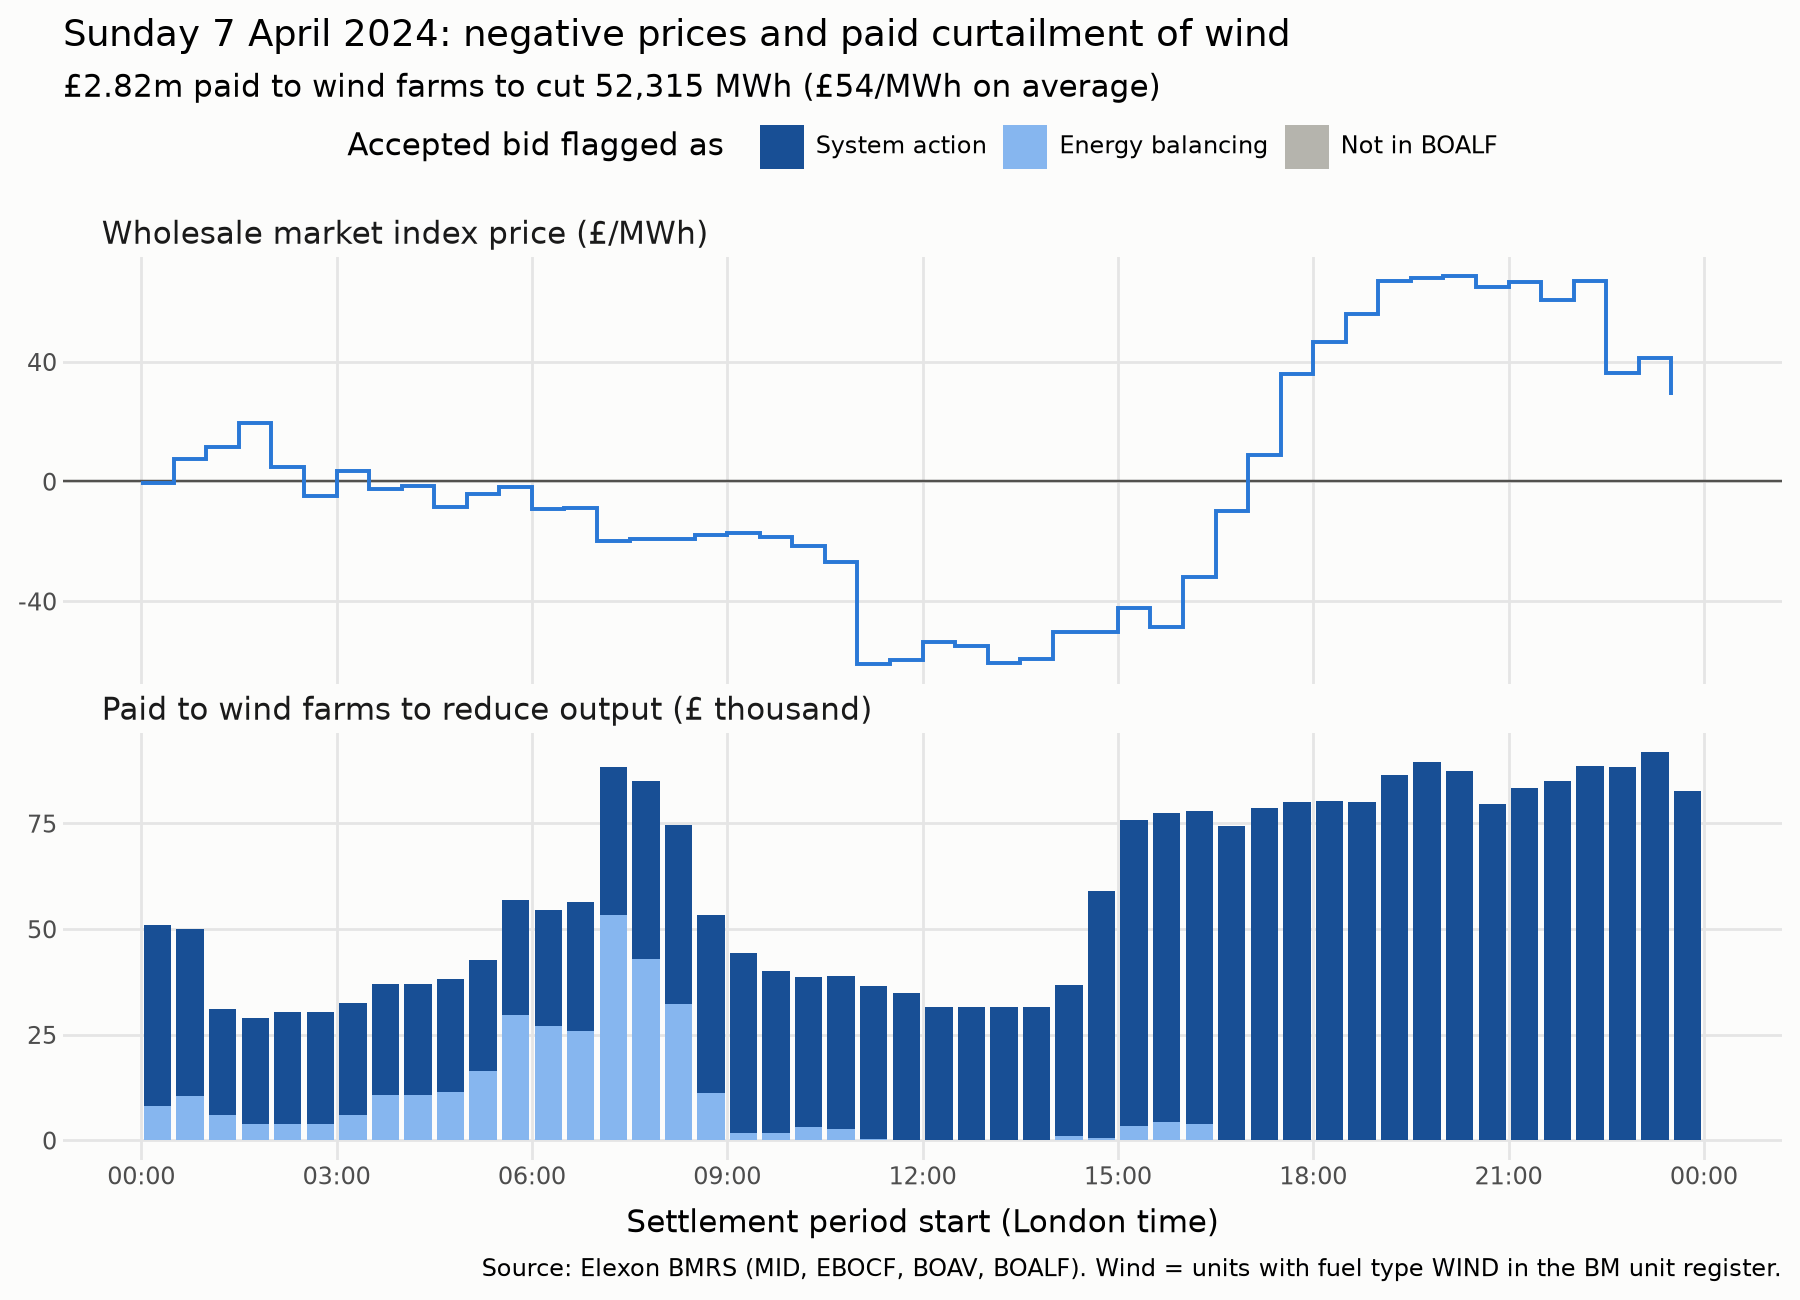

In [10]:
HOURS = [0, 3, 6, 9, 12, 15, 18, 21, 24]
PANELS = ["Wholesale market index price (£/MWh)", "Paid to wind farms to reduce output (£ thousand)"]
ACTIONS = ["System action", "Energy balancing", "Not in BOALF"]

# x = hours since local midnight, valid for 7 April (48 periods, no clock change)
price_df = mid.assign(hour=(mid["settlement_period"] - 1) / 2, panel=PANELS[0])
paid_df = (wind_bids.groupby(["settlement_period", "action"], as_index=False)["cash_gbp"].sum()
           .assign(hour=lambda d: (d["settlement_period"] - 1) / 2 + 0.25,
                   value=lambda d: d["cash_gbp"] / 1000, panel=PANELS[1]))
for d in (price_df, paid_df):
    d["panel"] = pd.Categorical(d["panel"], categories=PANELS)
paid_df["action"] = pd.Categorical(paid_df["action"], categories=ACTIONS)

curtailed_mwh = -wind_bids["volume_mwh"].sum()
fig2 = (
    ggplot()
    + geom_hline(data=price_df.head(1), mapping=aes(yintercept=0), color="#52514e", size=0.5)
    + geom_step(data=price_df, mapping=aes("hour", "price_gbp_mwh"), direction="hv", color="#2a78d6", size=0.8)
    + geom_col(data=paid_df, mapping=aes("hour", "value", fill="action"), width=0.42)
    + facet_wrap("panel", ncol=1, scales="free_y")
    + scale_fill_manual(values={"System action": "#184f95", "Energy balancing": "#86b6ef", "Not in BOALF": "#b5b4ad"},
                        drop=True)
    + scale_x_continuous(breaks=HOURS, labels=[f"{h % 24:02d}:00" for h in HOURS], limits=(0, 24))
    + labs(
        title="Sunday 7 April 2024: negative prices and paid curtailment of wind",
        subtitle=(f"£{wind_cash_total / 1e6:.2f}m paid to wind farms to cut {curtailed_mwh:,.0f} MWh "
                  f"(£{wind_cash_total / curtailed_mwh:.0f}/MWh on average)"),
        x="Settlement period start (London time)", y="", fill="Accepted bid flagged as",
        caption="Source: Elexon BMRS (MID, EBOCF, BOAV, BOALF). Wind = units with fuel type WIND in the BM unit register.",
    )
    + theme_minimal(base_size=11)
    + theme(
        figure_size=(9, 6.5),
        legend_position="top",
        panel_grid_minor=element_blank(),
        strip_text=element_text(ha="left", size=11),
        plot_background=element_rect(fill="#fcfcfb", color="#fcfcfb"),
    )
)
fig2.save(FIG_DIR / f"stage02_curtailment_{DAY}.png", dpi=150, verbose=False)
fig2